# MLB Pitch Sequencing as a Markov Network (2025 Season)

**Carter Dibsie** · M.E. Systems Engineering, University of Virginia · Course project, Spring 2026

## What this notebook does
1. **Pulls real data:** every 2025 regular-season pitch from MLB Statcast, through the `pybaseball` API.
2. **Cleans it:** the cleaned dataset has 656,050 pitches.
3. **Models each pitch as a state:** a state is pitch type (fastball, breaking ball, off-speed) plus the count. That's 3 × 12 = 36 states.
4. **Builds a network:** a directed, weighted network of how pitchers move from one state to the next within an at-bat. It has 261 transitions.
5. **Analyzes the network:** PageRank and betweenness centrality, community detection, strong connectivity and clustering.
6. **Wraps it in a reusable class:** `PitchSequenceMarkovChain` turns the network into a Markov chain that **predicts the next pitch** for any pitch and count, and **simulates whole at-bats**.

## Key findings
- **Full counts dominate.** Fastball at 3-2 has the highest PageRank (0.42), well ahead of every other state.
- **The count splits into three phases.** Community detection separates early counts, pitcher-ahead counts (0-2, 1-2) and hitter-ahead or deep counts (2-x, 3-x).
- **Off-speed pitches link the phases.** Off-speed states have the highest betweenness centrality, so pitchers use them to move between phases of an at-bat.
- **3-0 is predictable.** After a 3-0 fastball, the next pitch is a fastball 80.5% of the time.

## How to run
Open in Google Colab and choose **Runtime → Run all**. Pulling the data takes about 3–5 minutes.


## Install packages

In [ ]:
!pip install pybaseball networkx pandas matplotlib seaborn pyarrow python-louvain -q

## Imports and constants

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

from pybaseball import statcast, cache
cache.enable()

BROAD_CATEGORIES = {
    'FF': 'Fastball', 'SI': 'Fastball', 'FC': 'Fastball',
    'SL': 'Breaking Ball', 'CU': 'Breaking Ball', 'KC': 'Breaking Ball',
    'SV': 'Breaking Ball', 'CS': 'Breaking Ball',
    'CH': 'Off-Speed', 'FS': 'Off-Speed', 'KN': 'Off-Speed',
    'EP': 'Off-Speed', 'FO': 'Off-Speed', 'SC': 'Off-Speed',
    'PO': 'Other',
}
VALID_PITCHES = set(BROAD_CATEGORIES.keys())
PITCH_TYPES = ['Fastball', 'Breaking Ball', 'Off-Speed']
ALL_COUNTS = [
    '0-0', '1-0', '2-0', '3-0',
    '0-1', '1-1', '2-1', '3-1',
    '0-2', '1-2', '2-2', '3-2',
]
BROAD_COLORS = {
    'Fastball':      '#E63946',
    'Breaking Ball': '#2A9D8F',
    'Off-Speed':     '#6A994E',
}
COMMUNITY_COLORS = [
    '#E63946', '#2A9D8F', '#6A994E', '#F4A261',
    '#A8DADC', '#457B9D', '#E9C46A', '#264653',
]
BG_DARK  = '#0D1117'
BG_PANEL = '#161B22'
print('Setup complete.')

Setup complete.


## Pull 2025 Statcast data

In [ ]:
print('Pulling 2025 Statcast data (3-5 minutes)...')

chunks = [
    ('2025-03-27', '2025-04-30'),
    ('2025-05-01', '2025-05-31'),
    ('2025-06-01', '2025-06-30'),
    ('2025-07-01', '2025-07-31'),
    ('2025-08-01', '2025-08-31'),
    ('2025-09-01', '2025-10-01'),
]

dfs = []
for s, e in chunks:
    print(f'  Fetching {s} → {e}...')
    try:
        chunk = statcast(start_dt=s, end_dt=e)
        dfs.append(chunk)
        print(f'    {len(chunk):,} pitches')
    except Exception as ex:
        print(f'    Warning: {ex}')

raw = pd.concat(dfs, ignore_index=True)
print(f'\nTotal: {len(raw):,} pitches pulled')

Pulling 2025 Statcast data (3-5 minutes)...
  Fetching 2025-03-27 → 2025-04-30...
This is a large query, it may take a moment to complete


    133,922 pitches
  Fetching 2025-05-01 → 2025-05-31...
This is a large query, it may take a moment to complete


    120,218 pitches
  Fetching 2025-06-01 → 2025-06-30...
This is a large query, it may take a moment to complete


    115,816 pitches
  Fetching 2025-07-01 → 2025-07-31...
This is a large query, it may take a moment to complete


    107,305 pitches
  Fetching 2025-08-01 → 2025-08-31...
This is a large query, it may take a moment to complete


    124,298 pitches
  Fetching 2025-09-01 → 2025-10-01...
This is a large query, it may take a moment to complete


    112,678 pitches

Total: 714,237 pitches pulled


## Clean the data

In [ ]:
cols_needed = [
    'game_pk', 'at_bat_number', 'pitch_number',
    'pitcher', 'player_name', 'pitch_type',
    'balls', 'strikes',
]
cols = [c for c in cols_needed if c in raw.columns]
df = raw[cols].copy()
df = df.dropna(subset=['pitch_type'])
df = df[df['pitch_type'].isin(VALID_PITCHES)]
df['pitch_broad'] = df['pitch_type'].map(BROAD_CATEGORIES)
df = df[df['pitch_broad'] != 'Other']
df['count'] = df['balls'].astype(str) + '-' + df['strikes'].astype(str)
df = df[df['count'].isin(ALL_COUNTS)]
df = df.sort_values(['game_pk', 'at_bat_number', 'pitch_number']).reset_index(drop=True)
df['state'] = df['pitch_broad'] + '\n' + df['count']

print(f'Clean dataset: {len(df):,} pitches')
print(f'Unique states observed: {df["state"].nunique()} / 36')
print('\nPitches per count:')
print(df['count'].value_counts().reindex(ALL_COUNTS).to_string())

Clean dataset: 656,050 pitches
Unique states observed: 36 / 36

Pitches per count:
count
0-0    169468
1-0     64773
2-0     22247
3-0      7089
0-1     84412
1-1     65740
2-1     34417
3-1     14471
0-2     42734
1-2     62791
2-2     54337
3-2     33571


## Build the 36-state network

In [ ]:
def build_36_state_network(df, min_transitions=30):
    transition_counts = defaultdict(int)

    for (game, ab), group in df.groupby(['game_pk', 'at_bat_number']):
        group = group.sort_values('pitch_number').reset_index(drop=True)
        for i in range(len(group) - 1):
            from_state = group.loc[i,   'state']
            to_state   = group.loc[i+1, 'state']
            transition_counts[(from_state, to_state)] += 1

    G = nx.DiGraph()
    for pitch in PITCH_TYPES:
        for count in ALL_COUNTS:
            G.add_node(f'{pitch}\n{count}', pitch=pitch, count=count)

    for (src, dst), cnt in transition_counts.items():
        if cnt >= min_transitions:
            G.add_edge(src, dst, weight=cnt)

    for node in G.nodes():
        out_edges = list(G.out_edges(node, data=True))
        total = sum(d['weight'] for _, _, d in out_edges)
        for _, dst, data in out_edges:
            G[node][dst]['probability'] = round(data['weight'] / total, 4) if total > 0 else 0

    print(f'36-State Network built:')
    print(f'  Nodes  : {G.number_of_nodes()}')
    print(f'  Edges  : {G.number_of_edges()}')
    print(f'  Density: {nx.density(G):.4f}')
    return G


G = build_36_state_network(df, min_transitions=30)

PITCH_Y = {'Fastball': 2, 'Breaking Ball': 1, 'Off-Speed': 0}
NODE_POS = {}
for node in G.nodes():
    pitch, count = node.split('\n')
    x = ALL_COUNTS.index(count)
    y = PITCH_Y[pitch]
    NODE_POS[node] = (x, y)

36-State Network built:
  Nodes  : 36
  Edges  : 261
  Density: 0.2071


## Network visualization

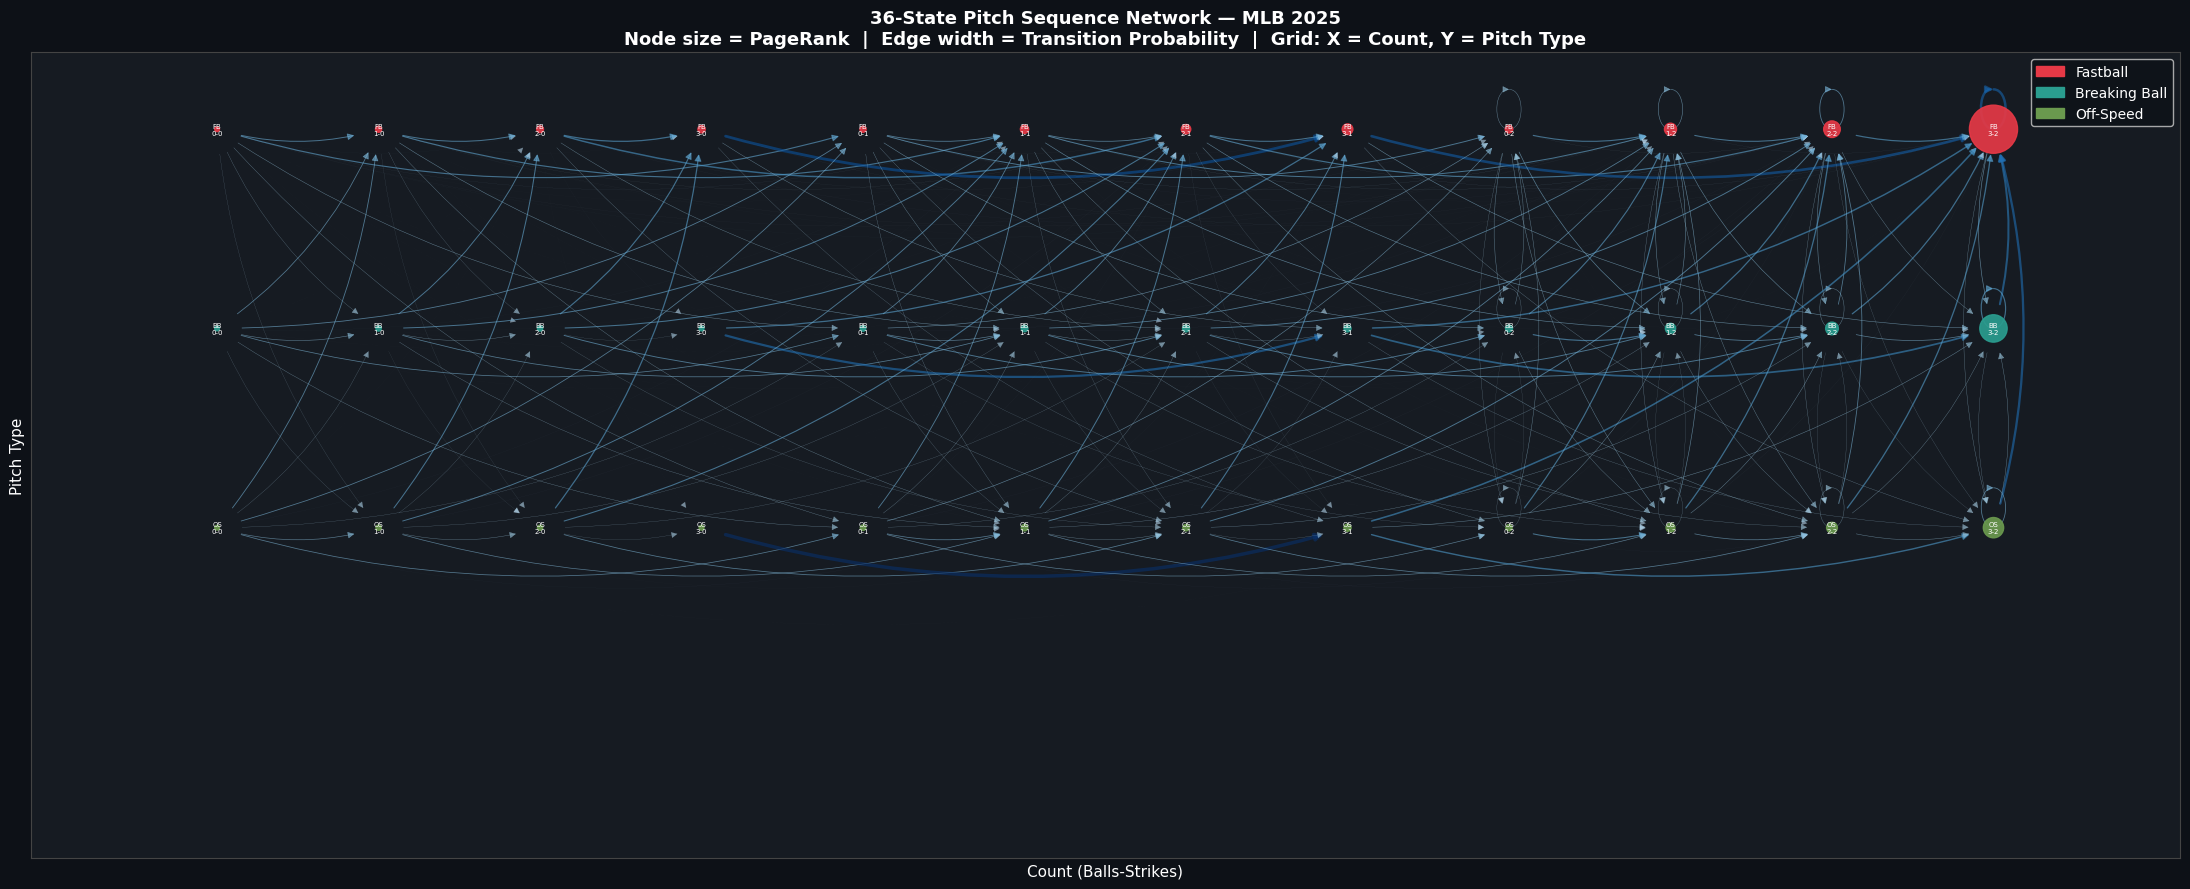

Saved network_36state.png


In [ ]:
def plot_36_state_network(G, NODE_POS):
    fig, ax = plt.subplots(figsize=(22, 9))
    fig.patch.set_facecolor(BG_DARK)
    ax.set_facecolor(BG_PANEL)

    pr = nx.pagerank(G, weight='weight')
    max_pr = max(pr.values())

    node_colors = [BROAD_COLORS[G.nodes[n]['pitch']] for n in G.nodes()]
    node_sizes  = [pr[n] / max_pr * 1200 for n in G.nodes()]

    edges        = list(G.edges())
    edge_weights = [G[u][v].get('probability', 0) for u, v in edges]
    max_w        = max(edge_weights) if edge_weights else 1

    nx.draw_networkx_edges(G, NODE_POS, ax=ax,
                           edgelist=edges,
                           width=[2.5 * w / max_w for w in edge_weights],
                           edge_color=[plt.cm.Blues(0.3 + 0.7 * w / max_w)
                                       for w in edge_weights],
                           arrows=True, arrowsize=10, alpha=0.6,
                           connectionstyle='arc3,rad=0.15',
                           min_source_margin=18, min_target_margin=18)

    nx.draw_networkx_nodes(G, NODE_POS, ax=ax,
                           node_color=node_colors,
                           node_size=node_sizes, alpha=0.92)

    short_labels = {n: n.replace('Breaking Ball', 'BB')
                        .replace('Off-Speed', 'OS')
                        .replace('Fastball', 'FB') for n in G.nodes()}
    nx.draw_networkx_labels(G, NODE_POS, labels=short_labels,
                            ax=ax, font_size=5, font_color='white')

    ax.set_xticks(range(len(ALL_COUNTS)))
    ax.set_xticklabels(ALL_COUNTS, color='white', fontsize=10)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(['Off-Speed', 'Breaking Ball', 'Fastball'],
                       color='white', fontsize=11)
    ax.tick_params(colors='white')
    ax.set_xlabel('Count (Balls-Strikes)', color='white', fontsize=11)
    ax.set_ylabel('Pitch Type', color='white', fontsize=11)
    for spine in ax.spines.values():
        spine.set_edgecolor('#444444')

    legend_patches = [mpatches.Patch(color=c, label=p)
                      for p, c in BROAD_COLORS.items()]
    ax.legend(handles=legend_patches, loc='upper right',
              facecolor=BG_DARK, labelcolor='white', fontsize=10)

    ax.set_title('36-State Pitch Sequence Network — MLB 2025\n'
                 'Node size = PageRank  |  Edge width = Transition Probability  |  '
                 'Grid: X = Count, Y = Pitch Type',
                 color='white', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('network_36state.png', dpi=150,
                bbox_inches='tight', facecolor=BG_DARK)
    plt.show()
    print('Saved network_36state.png')

plot_36_state_network(G, NODE_POS)

## Centrality

In [ ]:
def compute_centrality(G):
    wcc   = max(nx.weakly_connected_components(G), key=len)
    G_wcc = G.subgraph(wcc).copy()

    pagerank    = nx.pagerank(G, weight='weight')
    betweenness = nx.betweenness_centrality(G, weight='weight', normalized=True)
    closeness   = nx.closeness_centrality(G_wcc)
    in_degree   = nx.in_degree_centrality(G)
    out_degree  = nx.out_degree_centrality(G)

    rows = []
    for node in G.nodes():
        pitch, count = node.split('\n')
        rows.append({
            'node':        node,
            'pitch':       pitch,
            'count':       count,
            'pagerank':    round(pagerank.get(node, 0), 5),
            'betweenness': round(betweenness.get(node, 0), 5),
            'closeness':   round(closeness.get(node, 0), 5),
            'in_degree':   round(in_degree.get(node, 0), 5),
            'out_degree':  round(out_degree.get(node, 0), 5),
        })
    return pd.DataFrame(rows)


df_centrality = compute_centrality(G)

print('Top 10 states by PageRank:')
print(df_centrality.sort_values('pagerank', ascending=False)
      [['pitch','count','pagerank','betweenness','closeness','in_degree']]
      .head(10).to_string(index=False))

print('\nTop 10 states by Betweenness:')
print(df_centrality.sort_values('betweenness', ascending=False)
      [['pitch','count','pagerank','betweenness','closeness']]
      .head(10).to_string(index=False))

Top 10 states by PageRank:
        pitch count  pagerank  betweenness  closeness  in_degree
     Fastball   3-2   0.41868      0.00504    0.62500    0.42857
Breaking Ball   3-2   0.13556      0.00420    0.55556    0.28571
    Off-Speed   3-2   0.07475      0.01597    0.50000    0.25714
     Fastball   2-2   0.04987      0.00168    0.56807    0.54286
Breaking Ball   2-2   0.02918      0.00840    0.45986    0.31429
     Fastball   1-2   0.02635      0.00252    0.43459    0.45714
    Off-Speed   2-2   0.02123      0.01933    0.48286    0.37143
     Fastball   3-1   0.02065      0.00168    0.38095    0.28571
Breaking Ball   1-2   0.01907      0.00588    0.37532    0.37143
     Fastball   2-1   0.01628      0.01092    0.37815    0.37143

Top 10 states by Betweenness:
        pitch count  pagerank  betweenness  closeness
    Off-Speed   0-2   0.00709      0.02017    0.20317
    Off-Speed   2-1   0.00758      0.01933    0.29221
    Off-Speed   2-2   0.02123      0.01933    0.48286
    Off-Spe

## Centrality heatmaps

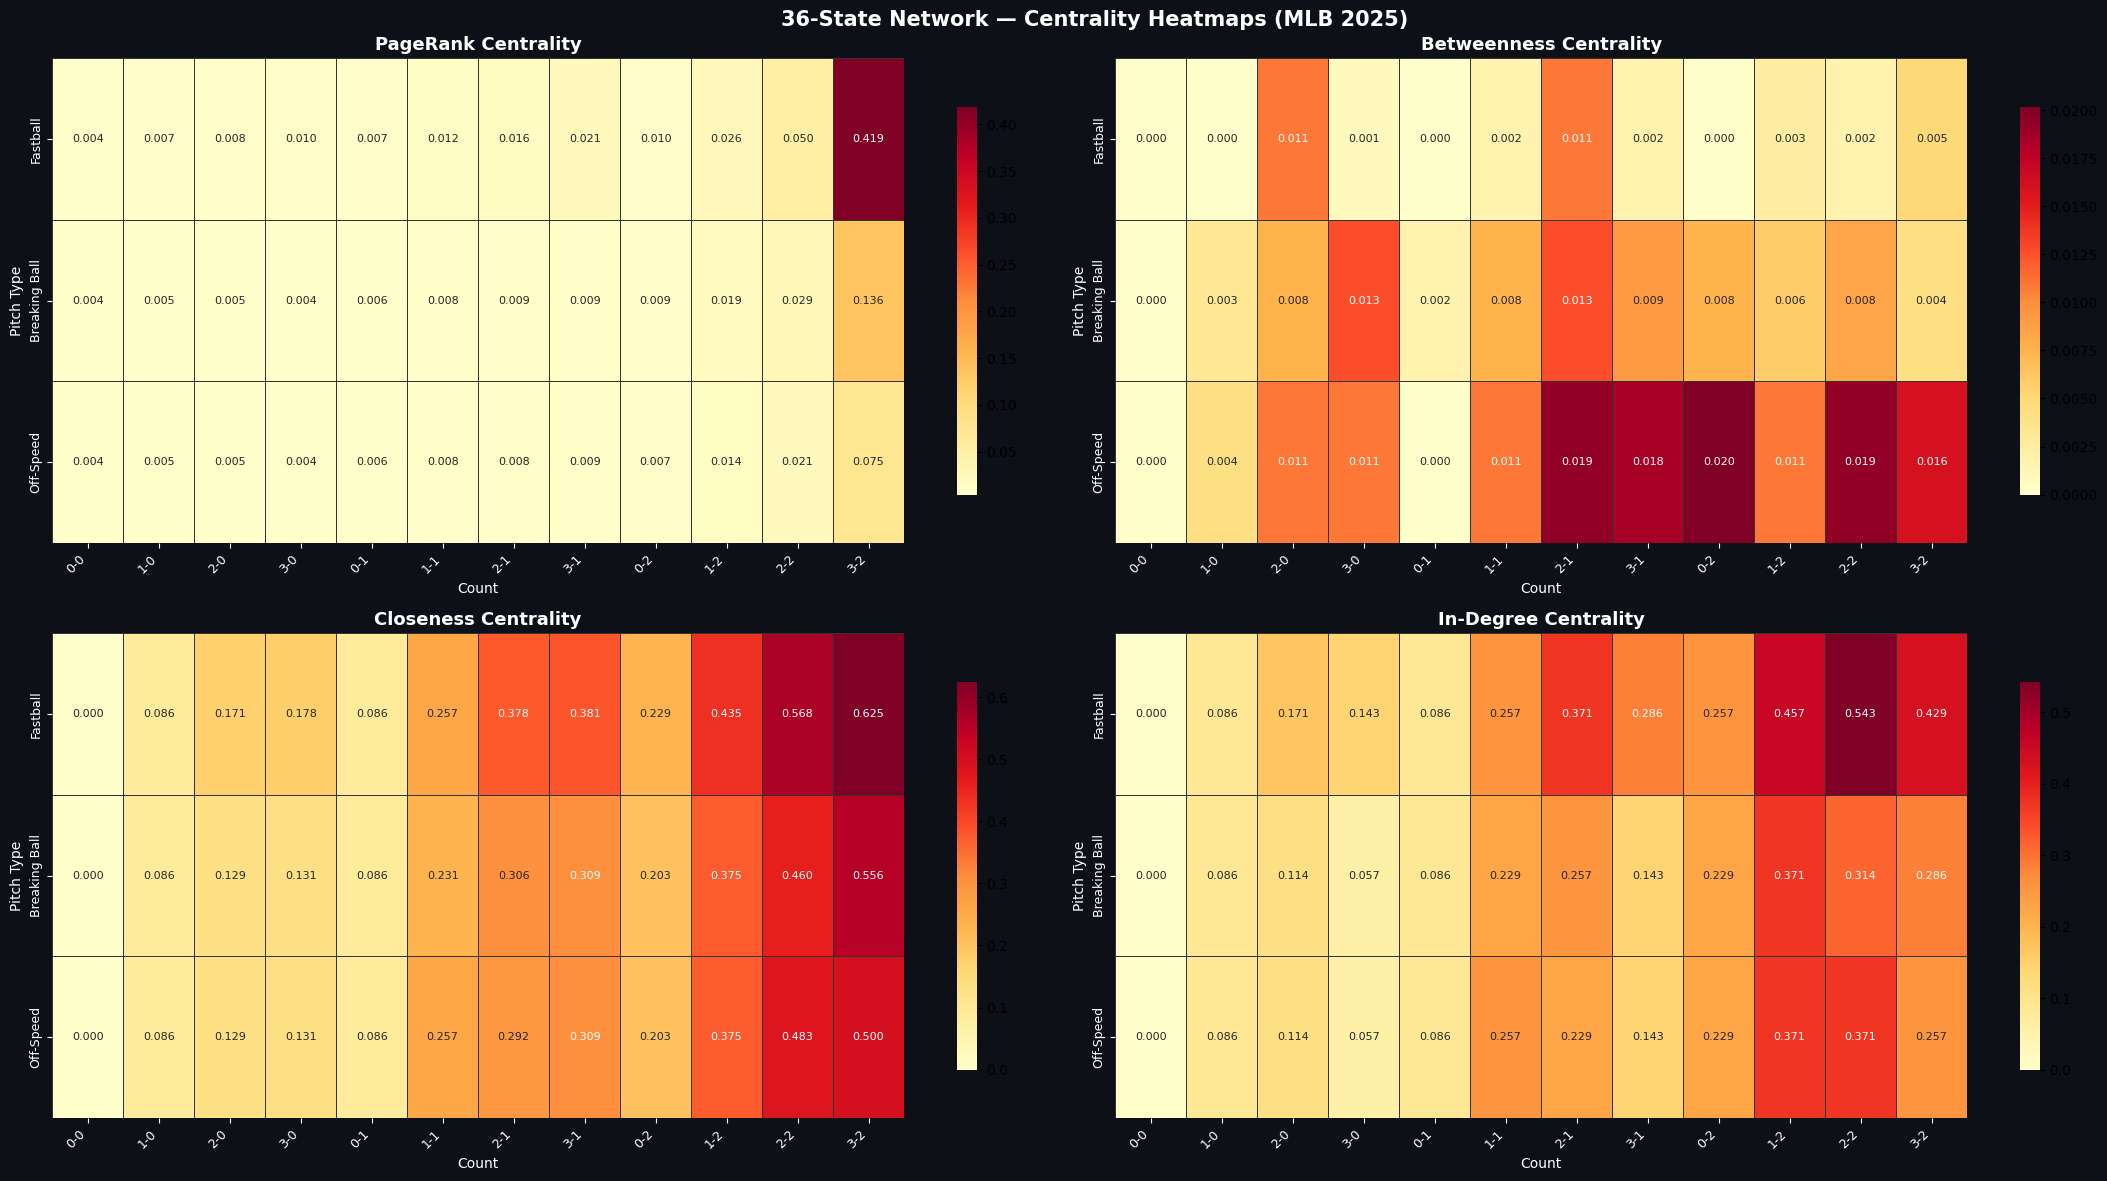

Saved centrality_heatmaps.png


In [ ]:
def plot_centrality_heatmaps(df_centrality):
    metrics = ['pagerank', 'betweenness', 'closeness', 'in_degree']
    titles  = ['PageRank', 'Betweenness', 'Closeness', 'In-Degree']

    fig, axes = plt.subplots(2, 2, figsize=(22, 12))
    fig.patch.set_facecolor(BG_DARK)
    axes = axes.flatten()

    for ax, metric, title in zip(axes, metrics, titles):
        pivot = df_centrality.pivot(index='pitch', columns='count', values=metric)
        pivot = pivot.reindex(index=PITCH_TYPES, columns=ALL_COUNTS)

        sns.heatmap(pivot, ax=ax, cmap='YlOrRd', annot=True, fmt='.3f',
                    linewidths=0.5, linecolor='#333333',
                    cbar_kws={'shrink': 0.8},
                    annot_kws={'size': 8})

        ax.set_title(f'{title} Centrality', color='white',
                     fontsize=13, fontweight='bold')
        ax.set_xlabel('Count', color='white', fontsize=10)
        ax.set_ylabel('Pitch Type', color='white', fontsize=10)
        ax.tick_params(colors='white', labelsize=9)
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

    fig.suptitle('36-State Network — Centrality Heatmaps (MLB 2025)',
                 color='white', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig('centrality_heatmaps.png', dpi=150,
                bbox_inches='tight', facecolor=BG_DARK)
    plt.show()
    print('Saved centrality_heatmaps.png')

plot_centrality_heatmaps(df_centrality)

## Centrality by pitch type

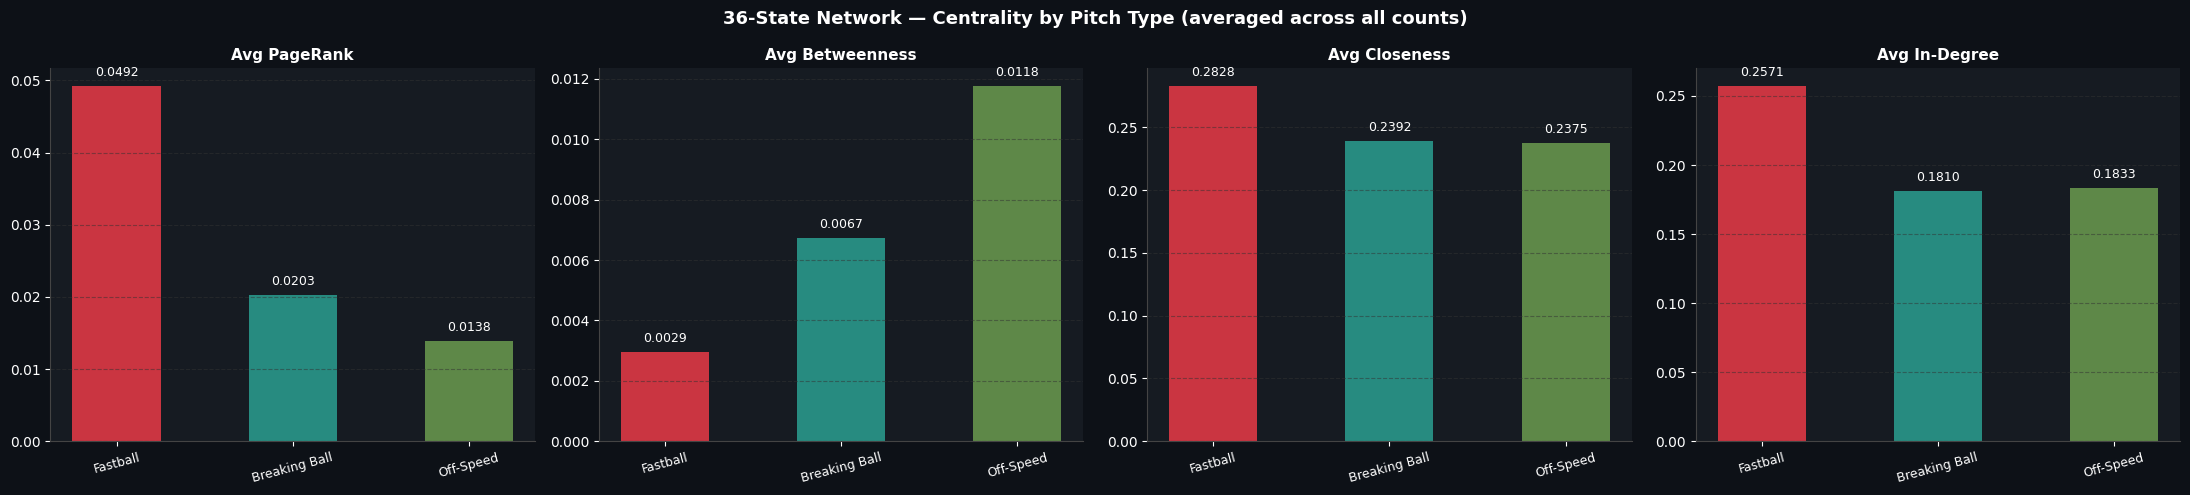

Saved centrality_by_pitch.png


In [ ]:
def plot_centrality_by_pitch(df_centrality):
    agg = df_centrality.groupby('pitch')[
        ['pagerank','betweenness','closeness','in_degree']].mean()
    agg = agg.reindex(PITCH_TYPES)

    metrics = ['pagerank', 'betweenness', 'closeness', 'in_degree']
    titles  = ['Avg PageRank', 'Avg Betweenness', 'Avg Closeness', 'Avg In-Degree']

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.patch.set_facecolor(BG_DARK)

    for ax, metric, title in zip(axes, metrics, titles):
        ax.set_facecolor(BG_PANEL)
        colors = [BROAD_COLORS[p] for p in agg.index]
        bars = ax.bar(agg.index, agg[metric], color=colors, alpha=0.87, width=0.5)
        ax.set_title(title, color='white', fontsize=11, fontweight='bold')
        ax.tick_params(colors='white')
        ax.set_xticklabels(agg.index, color='white', fontsize=9, rotation=15)
        ax.spines[['top', 'right']].set_visible(False)
        for spine in ax.spines.values():
            spine.set_edgecolor('#444444')
        ax.grid(axis='y', color='#333333', linestyle='--', alpha=0.5)
        for bar, val in zip(bars, agg[metric]):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + agg[metric].max() * 0.02,
                    f'{val:.4f}', ha='center', va='bottom',
                    color='white', fontsize=9)

    fig.suptitle('36-State Network — Centrality by Pitch Type (averaged across all counts)',
                 color='white', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('centrality_by_pitch.png', dpi=150,
                bbox_inches='tight', facecolor=BG_DARK)
    plt.show()
    print('Saved centrality_by_pitch.png')

plot_centrality_by_pitch(df_centrality)

## Degree distribution

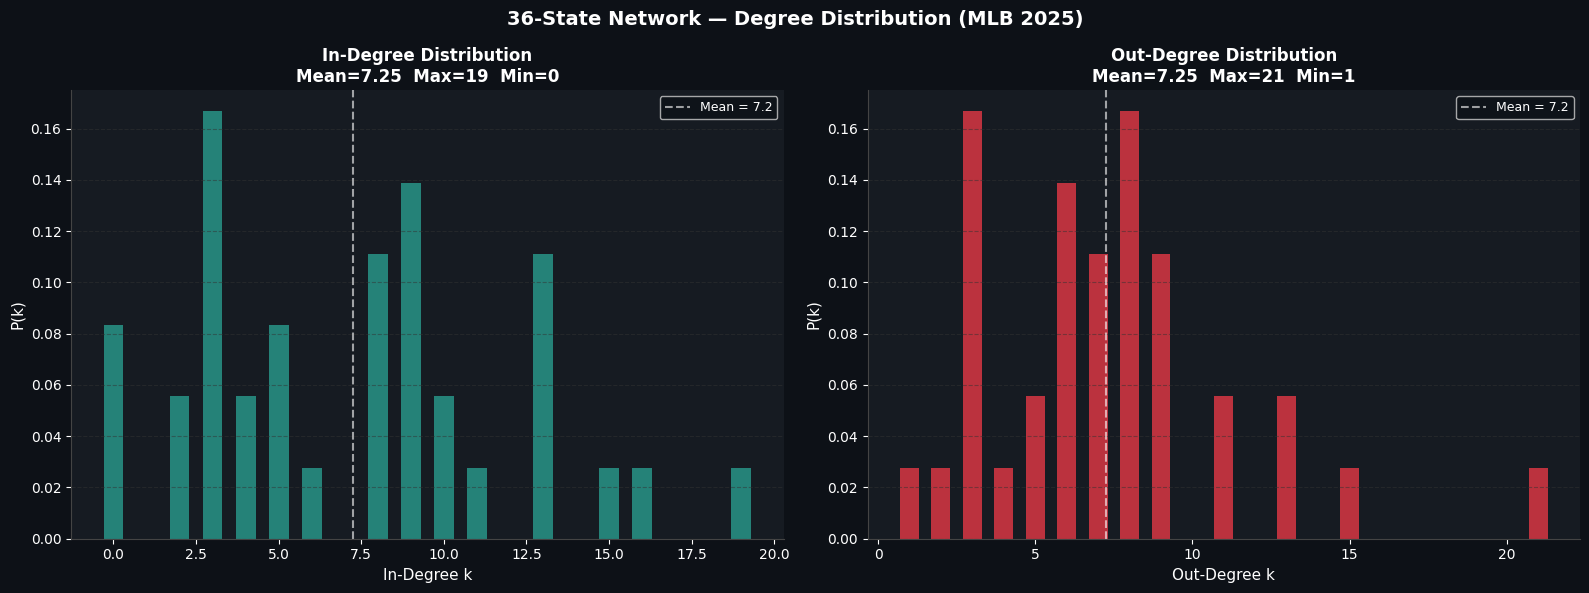

Saved degree_distribution.png

In-degree  — mean: 7.25, max: 19, min: 0
Out-degree — mean: 7.25, max: 21, min: 1


In [ ]:
def plot_degree_distribution(G):
    in_degrees  = [d for _, d in G.in_degree()]
    out_degrees = [d for _, d in G.out_degree()]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.patch.set_facecolor(BG_DARK)

    for ax, degrees, label, color in zip(
        axes,
        [in_degrees, out_degrees],
        ['In-Degree', 'Out-Degree'],
        ['#2A9D8F', '#E63946']
    ):
        ax.set_facecolor(BG_PANEL)
        counts_arr = np.bincount(degrees)
        k_vals = np.nonzero(counts_arr)[0]
        p_vals = counts_arr[k_vals] / len(degrees)

        ax.bar(k_vals, p_vals, color=color, alpha=0.8, width=0.6)
        ax.set_xlabel(f'{label} k', color='white', fontsize=11)
        ax.set_ylabel('P(k)', color='white', fontsize=11)
        ax.set_title(f'{label} Distribution\n'
                     f'Mean={np.mean(degrees):.2f}  '
                     f'Max={max(degrees)}  Min={min(degrees)}',
                     color='white', fontsize=12, fontweight='bold')
        ax.tick_params(colors='white')
        ax.spines[['top', 'right']].set_visible(False)
        for spine in ax.spines.values():
            spine.set_edgecolor('#444444')
        ax.grid(axis='y', color='#333333', linestyle='--', alpha=0.5)
        ax.axvline(np.mean(degrees), color='white', linestyle='--',
                   alpha=0.6, linewidth=1.5,
                   label=f'Mean = {np.mean(degrees):.1f}')
        ax.legend(facecolor=BG_DARK, labelcolor='white', fontsize=9)

    fig.suptitle('36-State Network — Degree Distribution (MLB 2025)',
                 color='white', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('degree_distribution.png', dpi=150,
                bbox_inches='tight', facecolor=BG_DARK)
    plt.show()
    print('Saved degree_distribution.png')
    print(f'\nIn-degree  — mean: {np.mean(in_degrees):.2f}, '
          f'max: {max(in_degrees)}, min: {min(in_degrees)}')
    print(f'Out-degree — mean: {np.mean(out_degrees):.2f}, '
          f'max: {max(out_degrees)}, min: {min(out_degrees)}')

plot_degree_distribution(G)

## Community detection

In [ ]:
def detect_communities(G):
    G_und = G.to_undirected()
    isolated = list(nx.isolates(G_und))
    G_connected = G_und.copy()
    G_connected.remove_nodes_from(isolated)

    try:
        from community import community_louvain
        partition = community_louvain.best_partition(G_connected, weight='weight')
        method = 'Louvain'
    except (ImportError, AttributeError):
        try:
            import community_louvain
            partition = community_louvain.best_partition(G_connected, weight='weight')
            method = 'Louvain'
        except (ImportError, AttributeError):
            communities = nx.community.greedy_modularity_communities(
                G_connected, weight='weight')
            partition = {node: i for i, comm in enumerate(communities)
                         for node in comm}
            method = 'Greedy Modularity'

    next_id = max(partition.values()) + 1 if partition else 0
    for node in isolated:
        partition[node] = next_id
        next_id += 1

    print(f'Community Detection ({method}): '
          f'{len(set(partition.values()))} communities found')

    comm_summary = defaultdict(list)
    for node, comm in partition.items():
        pitch, count = node.split('\n')
        comm_summary[comm].append(f'{pitch} @ {count}')

    print('\nCommunity Composition:')
    for cid in sorted(comm_summary.keys()):
        members = sorted(comm_summary[cid])
        print(f'  Community {cid+1} ({len(members)} states):')
        for m in members:
            print(f'    {m}')

    return partition


partition = detect_communities(G)

Community Detection (Louvain): 3 communities found

Community Composition:
  Community 1 (11 states):
    Breaking Ball @ 0-0
    Breaking Ball @ 0-1
    Breaking Ball @ 1-0
    Fastball @ 0-0
    Fastball @ 0-1
    Fastball @ 1-0
    Fastball @ 1-1
    Off-Speed @ 0-0
    Off-Speed @ 0-1
    Off-Speed @ 1-0
    Off-Speed @ 1-1
  Community 2 (7 states):
    Breaking Ball @ 0-2
    Breaking Ball @ 1-1
    Breaking Ball @ 1-2
    Fastball @ 0-2
    Fastball @ 1-2
    Off-Speed @ 0-2
    Off-Speed @ 1-2
  Community 3 (18 states):
    Breaking Ball @ 2-0
    Breaking Ball @ 2-1
    Breaking Ball @ 2-2
    Breaking Ball @ 3-0
    Breaking Ball @ 3-1
    Breaking Ball @ 3-2
    Fastball @ 2-0
    Fastball @ 2-1
    Fastball @ 2-2
    Fastball @ 3-0
    Fastball @ 3-1
    Fastball @ 3-2
    Off-Speed @ 2-0
    Off-Speed @ 2-1
    Off-Speed @ 2-2
    Off-Speed @ 3-0
    Off-Speed @ 3-1
    Off-Speed @ 3-2


## Strong connectivity

In [ ]:
def analyze_strong_connectivity(G):
    sccs        = list(nx.strongly_connected_components(G))
    sccs_sorted = sorted(sccs, key=len, reverse=True)

    print('Strong Connectivity Analysis:')
    print(f'  Total SCCs            : {len(sccs)}')
    print(f'  Largest SCC size      : {len(sccs_sorted[0])} nodes')
    print(f'  Singleton SCCs        : {sum(1 for s in sccs if len(s) == 1)}')
    print(f'  Is strongly connected : {nx.is_strongly_connected(G)}')

    print(f'\nLargest SCC members ({len(sccs_sorted[0])} states):')
    for node in sorted(sccs_sorted[0]):
        print(f'  {node.replace(chr(10), " @ ")}')

    singletons = [list(s)[0] for s in sccs if len(s) == 1]
    if singletons:
        print(f'\nIsolated singleton states ({len(singletons)} total):')
        for node in sorted(singletons):
            in_w  = sum(d['weight'] for _, _, d in G.in_edges(node, data=True))
            out_w = sum(d['weight'] for _, _, d in G.out_edges(node, data=True))
            print(f'  {node.replace(chr(10), " @ "):30s} '
                  f'in={in_w:5d}  out={out_w:5d}')

    return sccs_sorted


sccs_sorted = analyze_strong_connectivity(G)

Strong Connectivity Analysis:
  Total SCCs            : 28
  Largest SCC size      : 3 nodes
  Singleton SCCs        : 24
  Is strongly connected : False

Largest SCC members (3 states):
  Breaking Ball @ 3-2
  Fastball @ 3-2
  Off-Speed @ 3-2

Isolated singleton states (24 total):
  Breaking Ball @ 0-0            in=    0  out=38755
  Breaking Ball @ 0-1            in=21098  out=17620
  Breaking Ball @ 1-0            in=14029  out=12303
  Breaking Ball @ 1-1            in=16498  out=13071
  Breaking Ball @ 2-0            in= 3634  out= 3226
  Breaking Ball @ 2-1            in= 7744  out= 6022
  Breaking Ball @ 3-0            in=  214  out=  133
  Breaking Ball @ 3-1            in= 1915  out= 1050
  Fastball @ 0-0                 in=    0  out=94110
  Fastball @ 0-1                 in=42926  out=36338
  Fastball @ 1-0                 in=38229  out=33153
  Fastball @ 1-1                 in=34843  out=27208
  Fastball @ 2-0                 in=15960  out=13131
  Fastball @ 2-1            

## Strong connectivity visualization

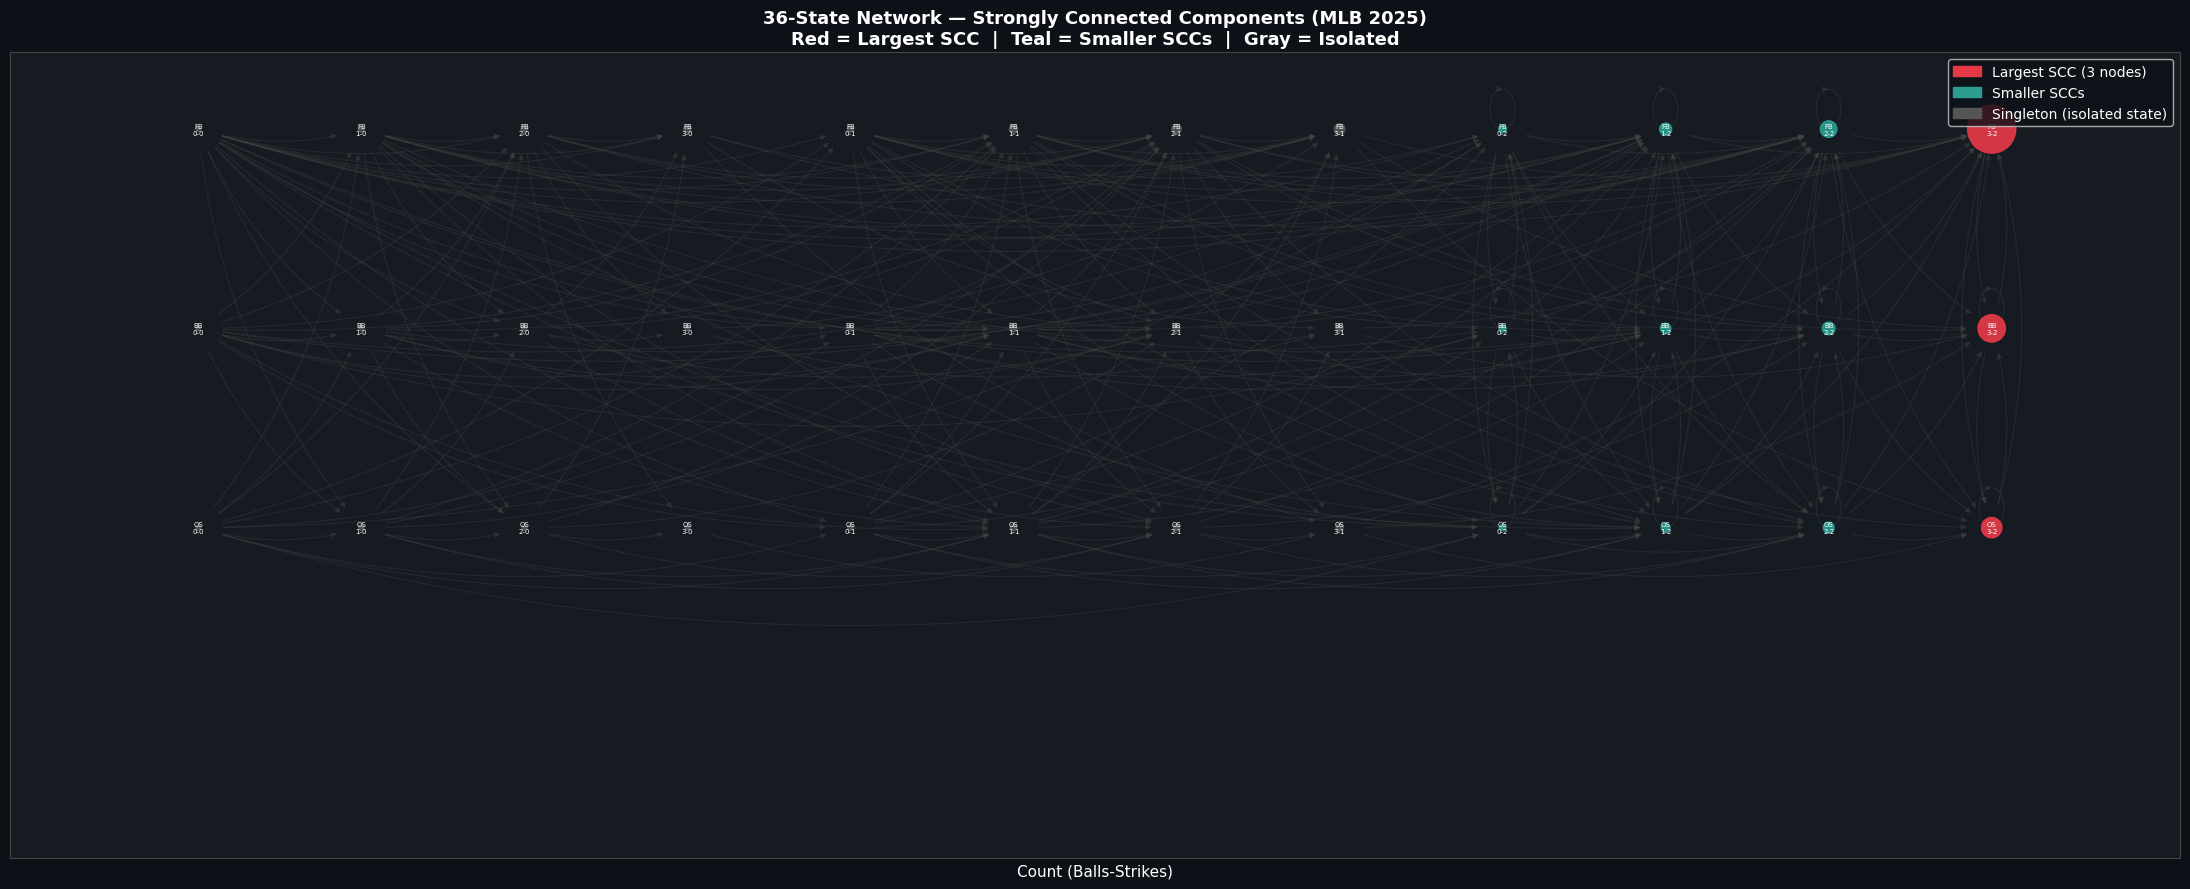

Saved strong_connectivity.png


In [ ]:
def plot_scc(G, NODE_POS, sccs_sorted):
    fig, ax = plt.subplots(figsize=(22, 9))
    fig.patch.set_facecolor(BG_DARK)
    ax.set_facecolor(BG_PANEL)

    largest_scc = sccs_sorted[0]
    scc_map = {}
    for i, scc in enumerate(sccs_sorted):
        for node in scc:
            scc_map[node] = i

    def node_color(n):
        idx = scc_map.get(n, len(sccs_sorted))
        if n in largest_scc:
            return '#E63946'
        elif idx < len(sccs_sorted) and len(sccs_sorted[idx]) > 1:
            return '#2A9D8F'
        else:
            return '#555555'

    pr     = nx.pagerank(G, weight='weight')
    max_pr = max(pr.values())
    node_colors = [node_color(n) for n in G.nodes()]
    node_sizes  = [pr[n] / max_pr * 1200 for n in G.nodes()]

    nx.draw_networkx_edges(G, NODE_POS, ax=ax,
                           edge_color='#444444', alpha=0.35,
                           arrows=True, arrowsize=8, width=0.8,
                           connectionstyle='arc3,rad=0.15',
                           min_source_margin=18, min_target_margin=18)
    nx.draw_networkx_nodes(G, NODE_POS, ax=ax,
                           node_color=node_colors,
                           node_size=node_sizes, alpha=0.92)
    short_labels = {n: n.replace('Breaking Ball', 'BB')
                        .replace('Off-Speed', 'OS')
                        .replace('Fastball', 'FB') for n in G.nodes()}
    nx.draw_networkx_labels(G, NODE_POS, labels=short_labels,
                            ax=ax, font_size=5, font_color='white')

    ax.set_xticks(range(len(ALL_COUNTS)))
    ax.set_xticklabels(ALL_COUNTS, color='white', fontsize=10)
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(['Off-Speed', 'Breaking Ball', 'Fastball'],
                       color='white', fontsize=11)
    ax.tick_params(colors='white')
    ax.set_xlabel('Count (Balls-Strikes)', color='white', fontsize=11)
    for spine in ax.spines.values():
        spine.set_edgecolor('#444444')

    legend_patches = [
        mpatches.Patch(color='#E63946',
                       label=f'Largest SCC ({len(largest_scc)} nodes)'),
        mpatches.Patch(color='#2A9D8F', label='Smaller SCCs'),
        mpatches.Patch(color='#555555', label='Singleton (isolated state)'),
    ]
    ax.legend(handles=legend_patches, loc='upper right',
              facecolor=BG_DARK, labelcolor='white', fontsize=10)
    ax.set_title('36-State Network — Strongly Connected Components (MLB 2025)\n'
                 'Red = Largest SCC  |  Teal = Smaller SCCs  |  Gray = Isolated',
                 color='white', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('strong_connectivity.png', dpi=150,
                bbox_inches='tight', facecolor=BG_DARK)
    plt.show()
    print('Saved strong_connectivity.png')

plot_scc(G, NODE_POS, sccs_sorted)

## Clustering coefficient

In [ ]:
def analyze_clustering(G):
    G_und     = G.to_undirected()
    local_cc  = nx.clustering(G_und, weight='weight')
    avg_cc    = nx.average_clustering(G_und, weight='weight')
    global_cc = nx.transitivity(G_und)

    print('Clustering Coefficient Analysis:')
    print(f'  Average clustering coefficient : {avg_cc:.4f}')
    print(f'  Global clustering (transitivity): {global_cc:.4f}')

    print('\nTop 10 states by local clustering coefficient:')
    top = sorted(local_cc.items(), key=lambda x: x[1], reverse=True)[:10]
    for node, cc in top:
        pitch, count = node.split('\n')
        print(f'  {pitch:15s} @ {count:5s}  CC = {cc:.4f}')

    print('\nBottom 5 states (least clustered):')
    bottom = sorted(local_cc.items(), key=lambda x: x[1])[:5]
    for node, cc in bottom:
        pitch, count = node.split('\n')
        print(f'  {pitch:15s} @ {count:5s}  CC = {cc:.4f}')

    return local_cc, avg_cc, global_cc


local_cc, avg_cc, global_cc = analyze_clustering(G)

Clustering Coefficient Analysis:
  Average clustering coefficient : 0.0137
  Global clustering (transitivity): 0.4846

Top 10 states by local clustering coefficient:
  Fastball        @ 0-2    CC = 0.0286
  Breaking Ball   @ 0-2    CC = 0.0284
  Fastball        @ 0-1    CC = 0.0268
  Fastball        @ 1-2    CC = 0.0242
  Fastball        @ 1-1    CC = 0.0219
  Breaking Ball   @ 0-1    CC = 0.0212
  Breaking Ball   @ 1-2    CC = 0.0212
  Breaking Ball   @ 2-2    CC = 0.0210
  Fastball        @ 0-0    CC = 0.0195
  Off-Speed       @ 0-1    CC = 0.0185

Bottom 5 states (least clustered):
  Off-Speed       @ 3-0    CC = 0.0000
  Breaking Ball   @ 3-0    CC = 0.0004
  Off-Speed       @ 3-1    CC = 0.0014
  Breaking Ball   @ 3-1    CC = 0.0023
  Off-Speed       @ 2-0    CC = 0.0042


## Clustering heatmap

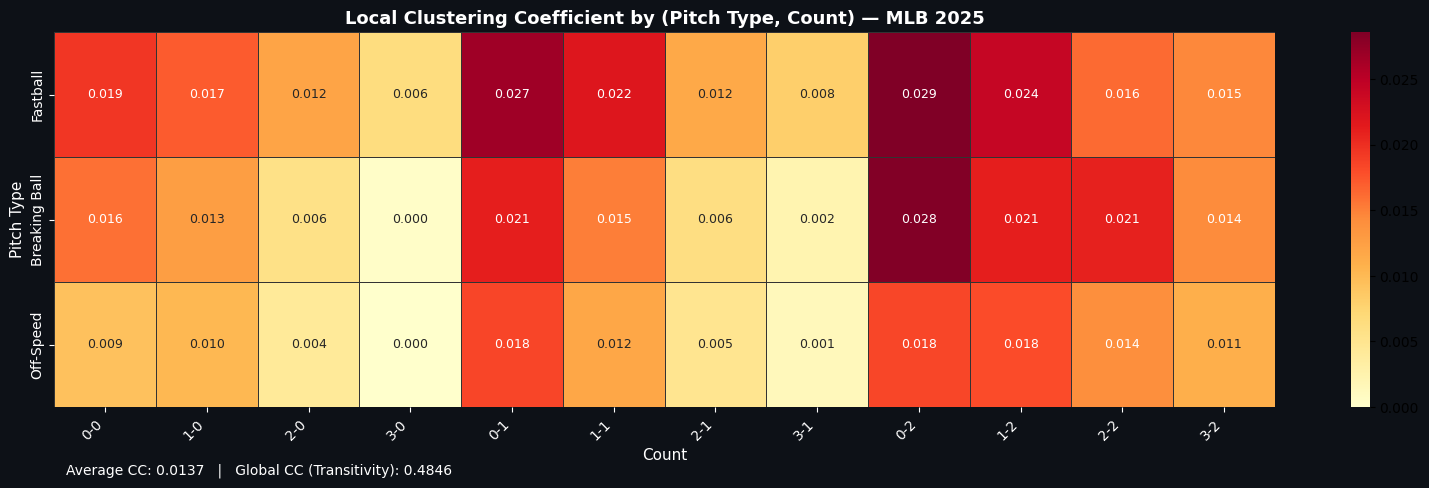

Saved clustering_heatmap.png


In [ ]:
def plot_clustering_heatmap(G, local_cc):
    rows = []
    for node, cc in local_cc.items():
        if '\n' not in node:
            continue
        pitch, count = node.split('\n')
        rows.append({'pitch': pitch, 'count': count, 'clustering': cc})

    df_cc  = pd.DataFrame(rows)
    pivot  = df_cc.pivot(index='pitch', columns='count', values='clustering')
    pivot  = pivot.reindex(index=PITCH_TYPES, columns=ALL_COUNTS)

    fig, ax = plt.subplots(figsize=(16, 5))
    fig.patch.set_facecolor(BG_DARK)
    ax.set_facecolor(BG_PANEL)

    sns.heatmap(pivot, ax=ax, cmap='YlOrRd', annot=True, fmt='.3f',
                linewidths=0.5, linecolor='#333333',
                annot_kws={'size': 9})
    ax.set_title('Local Clustering Coefficient by (Pitch Type, Count) — MLB 2025',
                 color='white', fontsize=13, fontweight='bold')
    ax.set_xlabel('Count', color='white', fontsize=11)
    ax.set_ylabel('Pitch Type', color='white', fontsize=11)
    ax.tick_params(colors='white')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45,
                       ha='right', color='white')
    ax.set_yticklabels(ax.get_yticklabels(), color='white')
    ax.text(0.01, -0.18,
            f'Average CC: {avg_cc:.4f}   |   '
            f'Global CC (Transitivity): {global_cc:.4f}',
            transform=ax.transAxes, color='white', fontsize=10)
    plt.tight_layout()
    plt.savefig('clustering_heatmap.png', dpi=150,
                bbox_inches='tight', facecolor=BG_DARK)
    plt.show()
    print('Saved clustering_heatmap.png')

plot_clustering_heatmap(G, local_cc)

## Markov chain model

In [ ]:
class PitchSequenceMarkovChain:
    def __init__(self, G):
        self.G      = G
        self.states = list(G.nodes())
        self._build_transition_matrix()

    def _build_transition_matrix(self):
        n = len(self.states)
        self.state_idx = {s: i for i, s in enumerate(self.states)}
        self.P = np.zeros((n, n))
        for i, src in enumerate(self.states):
            out_edges = list(self.G.out_edges(src, data=True))
            total = sum(d['weight'] for _, _, d in out_edges)
            if total > 0:
                for _, dst, data in out_edges:
                    j = self.state_idx.get(dst)
                    if j is not None:
                        self.P[i, j] = data['weight'] / total

    def predict(self, pitch_type, count, top_n=3):
        state = f'{pitch_type}\n{count}'
        if state not in self.state_idx:
            return f'State ({pitch_type}, {count}) not in network'
        i     = self.state_idx[state]
        probs = self.P[i]
        top_indices = np.argsort(probs)[::-1][:top_n]
        results = []
        for idx in top_indices:
            if probs[idx] > 0:
                next_state = self.states[idx]
                pitch, cnt = next_state.split('\n')
                results.append((pitch, cnt, round(probs[idx], 4)))
        return results

    def simulate_at_bat(self, start_pitch, start_count, n_pitches=8, seed=None):
        if seed is not None:
            np.random.seed(seed)
        state = f'{start_pitch}\n{start_count}'
        if state not in self.state_idx:
            return []
        sequence = [(start_pitch, start_count)]
        for _ in range(n_pitches - 1):
            i     = self.state_idx[state]
            probs = self.P[i]
            if probs.sum() == 0:
                break
            next_idx = np.random.choice(len(self.states),
                                        p=probs / probs.sum())
            state = self.states[next_idx]
            pitch, count = state.split('\n')
            sequence.append((pitch, count))
        return sequence

    def stationary_distribution(self):
        eigenvalues, eigenvectors = np.linalg.eig(self.P.T)
        idx        = np.argmin(np.abs(eigenvalues - 1))
        stationary = np.real(eigenvectors[:, idx])
        stationary = stationary / stationary.sum()
        result = {self.states[i]: round(float(stationary[i]), 6)
                  for i in range(len(self.states))}
        return dict(sorted(result.items(), key=lambda x: x[1], reverse=True))


markov = PitchSequenceMarkovChain(G)
print(f'Markov Chain built — transition matrix shape: {markov.P.shape}')
print(f'Non-zero transitions: {np.count_nonzero(markov.P)}')

Markov Chain built — transition matrix shape: (36, 36)
Non-zero transitions: 261


## Next-pitch predictions

In [ ]:
key_states = [
    ('Fastball',      '0-0'),
    ('Fastball',      '0-2'),
    ('Fastball',      '3-0'),
    ('Breaking Ball', '0-2'),
    ('Breaking Ball', '3-2'),
    ('Off-Speed',     '1-2'),
    ('Fastball',      '3-2'),
]

print('=== 36-State Markov Chain Predictions ===')
print('Given current (Pitch, Count) → Top 3 most likely next states\n')
for pitch, count in key_states:
    preds = markov.predict(pitch, count, top_n=3)
    print(f'  [{pitch} @ {count}]')
    if isinstance(preds, str):
        print(f'    {preds}')
    else:
        for next_pitch, next_count, prob in preds:
            print(f'    → {next_pitch:15s} @ {next_count:5s}  {prob:.1%}')
    print()

=== 36-State Markov Chain Predictions ===
Given current (Pitch, Count) → Top 3 most likely next states

  [Fastball @ 0-0]
    → Fastball        @ 0-1    32.5%
    → Fastball        @ 1-0    27.9%
    → Breaking Ball   @ 0-1    12.8%

  [Fastball @ 0-2]
    → Fastball        @ 1-2    31.6%
    → Breaking Ball   @ 1-2    19.7%
    → Fastball        @ 0-2    13.3%

  [Fastball @ 3-0]
    → Fastball        @ 3-1    80.5%
    → Breaking Ball   @ 3-1    11.8%
    → Off-Speed       @ 3-1    6.6%

  [Breaking Ball @ 0-2]
    → Breaking Ball   @ 1-2    33.3%
    → Fastball        @ 1-2    32.1%
    → Fastball        @ 0-2    12.2%

  [Breaking Ball @ 3-2]
    → Fastball        @ 3-2    57.9%
    → Breaking Ball   @ 3-2    33.9%
    → Off-Speed       @ 3-2    8.2%

  [Off-Speed @ 1-2]
    → Fastball        @ 2-2    36.9%
    → Off-Speed       @ 2-2    19.5%
    → Fastball        @ 1-2    17.3%

  [Fastball @ 3-2]
    → Fastball        @ 3-2    71.6%
    → Breaking Ball   @ 3-2    18.5%
    → Of

## Simulated at-bats

In [ ]:
print('=== Simulated At-Bat Sequences ===\n')

scenarios = [
    ('Fastball',      '0-0', 'Typical at-bat starting with first-pitch fastball'),
    ('Breaking Ball', '0-2', 'Pitcher ahead, started with breaking ball'),
    ('Fastball',      '3-0', 'Full hitter count — fastball heavy'),
]

for start_pitch, start_count, desc in scenarios:
    print(f'Scenario: {desc}')
    seq = markov.simulate_at_bat(start_pitch, start_count,
                                  n_pitches=7, seed=42)
    for step, (p, c) in enumerate(seq):
        marker = '►' if step == 0 else ' '
        print(f'  {marker} Pitch {step+1}: {p:15s} @ {c}')
    print()

=== Simulated At-Bat Sequences ===

Scenario: Typical at-bat starting with first-pitch fastball
  ► Pitch 1: Fastball        @ 0-0
    Pitch 2: Fastball        @ 0-1
    Pitch 3: Off-Speed       @ 0-2
    Pitch 4: Off-Speed       @ 1-2
    Pitch 5: Breaking Ball   @ 1-2
    Pitch 6: Fastball        @ 1-2
    Pitch 7: Fastball        @ 1-2

Scenario: Pitcher ahead, started with breaking ball
  ► Pitch 1: Breaking Ball   @ 0-2
    Pitch 2: Fastball        @ 1-2
    Pitch 3: Off-Speed       @ 2-2
    Pitch 4: Breaking Ball   @ 3-2
    Pitch 5: Breaking Ball   @ 3-2
    Pitch 6: Fastball        @ 3-2
    Pitch 7: Fastball        @ 3-2

Scenario: Full hitter count — fastball heavy
  ► Pitch 1: Fastball        @ 3-0
    Pitch 2: Fastball        @ 3-1
    Pitch 3: Off-Speed       @ 3-2
    Pitch 4: Breaking Ball   @ 3-2
    Pitch 5: Breaking Ball   @ 3-2
    Pitch 6: Fastball        @ 3-2
    Pitch 7: Fastball        @ 3-2



## Stationary distribution

=== Stationary Distribution — Top 15 States ===
(Long-run probability of being in each state)

   1. Fastball        @ 3-2    0.6807  (68.1%)
   2. Breaking Ball   @ 3-2    0.2095  (20.9%)
   3. Off-Speed       @ 3-2    0.1098  (11.0%)
   4. Fastball        @ 0-0    0.0000  (0.0%)
   5. Fastball        @ 1-0    0.0000  (0.0%)
   6. Fastball        @ 2-0    0.0000  (0.0%)
   7. Fastball        @ 3-0    0.0000  (0.0%)
   8. Fastball        @ 0-1    0.0000  (0.0%)
   9. Fastball        @ 1-1    0.0000  (0.0%)
  10. Fastball        @ 2-1    0.0000  (0.0%)
  11. Fastball        @ 3-1    0.0000  (0.0%)
  12. Fastball        @ 0-2    -0.0000  (-0.0%)
  13. Fastball        @ 1-2    0.0000  (0.0%)
  14. Fastball        @ 2-2    0.0000  (0.0%)
  15. Breaking Ball   @ 0-0    0.0000  (0.0%)


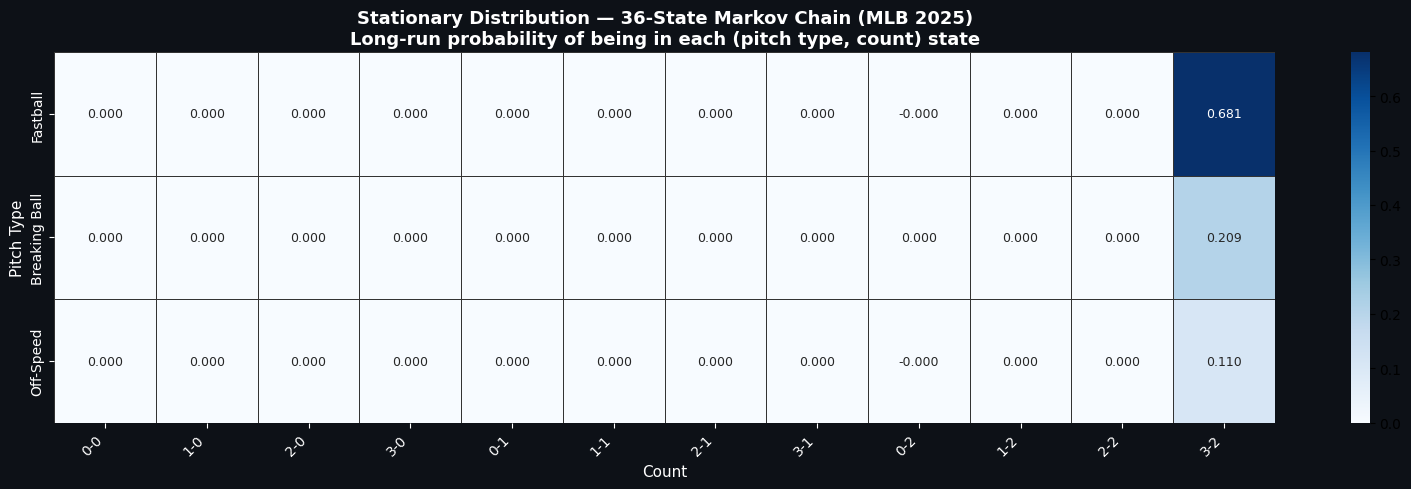

Saved stationary_distribution.png


In [ ]:
stationary = markov.stationary_distribution()

print('=== Stationary Distribution — Top 15 States ===')
print('(Long-run probability of being in each state)\n')
for i, (state, prob) in enumerate(list(stationary.items())[:15]):
    pitch, count = state.split('\n')
    print(f'  {i+1:2d}. {pitch:15s} @ {count:5s}  {prob:.4f}  ({prob:.1%})')

stat_rows = []
for state, prob in stationary.items():
    if '\n' in state:
        pitch, count = state.split('\n')
        stat_rows.append({'pitch': pitch, 'count': count, 'prob': prob})

df_stat    = pd.DataFrame(stat_rows)
pivot_stat = df_stat.pivot(index='pitch', columns='count', values='prob')
pivot_stat = pivot_stat.reindex(index=PITCH_TYPES, columns=ALL_COUNTS)

fig, ax = plt.subplots(figsize=(16, 5))
fig.patch.set_facecolor(BG_DARK)
ax.set_facecolor(BG_PANEL)
sns.heatmap(pivot_stat, ax=ax, cmap='Blues', annot=True, fmt='.3f',
            linewidths=0.5, linecolor='#333333',
            annot_kws={'size': 9})
ax.set_title('Stationary Distribution — 36-State Markov Chain (MLB 2025)\n'
             'Long-run probability of being in each (pitch type, count) state',
             color='white', fontsize=13, fontweight='bold')
ax.set_xlabel('Count', color='white', fontsize=11)
ax.set_ylabel('Pitch Type', color='white', fontsize=11)
ax.tick_params(colors='white')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', color='white')
ax.set_yticklabels(ax.get_yticklabels(), color='white')
plt.tight_layout()
plt.savefig('stationary_distribution.png', dpi=150,
            bbox_inches='tight', facecolor=BG_DARK)
plt.show()
print('Saved stationary_distribution.png')

## Summary

In [ ]:
print('=' * 55)
print('NETWORK SUMMARY — MLB 2025 Pitch Sequence Network')
print('=' * 55)
print(f'  Nodes (states)          : {G.number_of_nodes()}')
print(f'  Edges (transitions)     : {G.number_of_edges()}')
print(f'  Network density         : {nx.density(G):.4f}')
print(f'  Is strongly connected   : {nx.is_strongly_connected(G)}')
print(f'  # Strongly conn. comps  : {nx.number_strongly_connected_components(G)}')
print(f'  Largest SCC size        : {len(sccs_sorted[0])}')
print(f'  Avg clustering coeff    : {avg_cc:.4f}')
print(f'  Global clustering coeff : {global_cc:.4f}')
print()
print('Top 5 states by PageRank:')
for _, row in df_centrality.sort_values('pagerank', ascending=False).head(5).iterrows():
    print(f'  {row["pitch"]:15s} @ {row["count"]:5s}  PR={row["pagerank"]:.4f}')
print()
print('Top 5 states by Betweenness:')
for _, row in df_centrality.sort_values('betweenness', ascending=False).head(5).iterrows():
    print(f'  {row["pitch"]:15s} @ {row["count"]:5s}  BC={row["betweenness"]:.4f}')
print()
print(f'Communities detected      : {len(set(partition.values()))}')
print(f'Stationary dist. top state: '
      f'{list(stationary.keys())[0].replace(chr(10), " @ ")} '
      f'({list(stationary.values())[0]:.1%})')

NETWORK SUMMARY — MLB 2025 Pitch Sequence Network
  Nodes (states)          : 36
  Edges (transitions)     : 261
  Network density         : 0.2071
  Is strongly connected   : False
  # Strongly conn. comps  : 28
  Largest SCC size        : 3
  Avg clustering coeff    : 0.0137
  Global clustering coeff : 0.4846

Top 5 states by PageRank:
  Fastball        @ 3-2    PR=0.4187
  Breaking Ball   @ 3-2    PR=0.1356
  Off-Speed       @ 3-2    PR=0.0747
  Fastball        @ 2-2    PR=0.0499
  Breaking Ball   @ 2-2    PR=0.0292

Top 5 states by Betweenness:
  Off-Speed       @ 0-2    BC=0.0202
  Off-Speed       @ 2-1    BC=0.0193
  Off-Speed       @ 2-2    BC=0.0193
  Off-Speed       @ 3-1    BC=0.0185
  Off-Speed       @ 3-2    BC=0.0160

Communities detected      : 3
Stationary dist. top state: Fastball @ 3-2 (68.1%)
